# 🔑 Solutions · Lesson 04: Smoothing Forecasters: Moving Average, SES, Holt & Holt-Winters

> Try every problem yourself first! Peek at hints before peeking here. Run the setup cell, then read each solution **and its explanation**: there is often more than one valid way.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

### ✅ Solution 4.1 · Simple exponential smoothing by hand

**Problem recap:** Implement SES with a `for` loop: `level = alpha*y_t + (1-alpha)*level`, starting with `level = y[0]`.
  For `y = [3, 5, 9, 20, 12, 17, 22, 23, 51, 41]` and `alpha = 0.3`, what is the **forecast for the next period**? Store it in `my_forecast`.
  Then verify against `statsmodels`.

In [2]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
y = [3, 5, 9, 20, 12, 17, 22, 23, 51, 41]
alpha = 0.3
level = y[0]
for obs in y[1:]:
    level = alpha * obs + (1 - alpha) * level
my_forecast = level
print('by hand   :', round(my_forecast, 4))
print('statsmodels:', SimpleExpSmoothing(y, initialization_method='known', initial_level=y[0]).fit(smoothing_level=0.3, optimized=False).forecast(1))
check('SES forecast', my_forecast, 31.62, tol=0.01)

by hand   : 31.6201
statsmodels: [31.62014545]
✅ SES forecast: correct!


**Why this works:** Each new level is a blend: 30 % of the newest observation plus 70 % of the old level. Unrolling the recursion shows every past observation contributes with weight α(1−α)ᵏ: exponentially decaying memory.

### ✅ Solution 4.2 · Moving-average window shootout

**Problem recap:** Walk-forward evaluate moving-average forecasters on **maize** with windows `w ∈ {1, 2, 4, 8, 13, 26}` (horizon 4, `initial=470`, `step=2`) and print MAE for each.
  (`w = 1` is the naive forecast.) Which window wins, and what does that tell you about the series?

In [3]:
s = load_weekly('maize')['price']
out = {}
for w in [1, 2, 4, 8, 13, 26]:
    f = lambda tr, h, w=w: fc_ma(tr, h, w)
    wf = walk_forward(s, f, initial=470, horizon=4, step=2)
    out[w] = mae(wf.actual, wf.forecast)
pd.Series(out, name='MAE').rename_axis('window').round(2)

window
1      6.19
2      6.83
4      8.01
8     10.38
13    13.10
26    16.97
Name: MAE, dtype: float64

**Why this works:** A moving average has a **lag**: the longer the window, the more old data it averages in. For a trending series like maize the shortest windows win. If the series were pure noise around a constant, a *long* window would win. Choosing the window is the classic bias–variance trade-off.

### ✅ Solution 4.3 · SES vs Holt vs damped Holt on rice

**Problem recap:** Hold out the last 26 weeks of **rice**. Fit `SimpleExpSmoothing`, `Holt` and `Holt(damped_trend=True)` on the training part (all with `initialization_method='estimated'`).
  Plot the three 26-week forecasts and print a score table. Report the fitted `smoothing_level` (α) and `smoothing_trend` (β) of Holt. What do they say about the series?

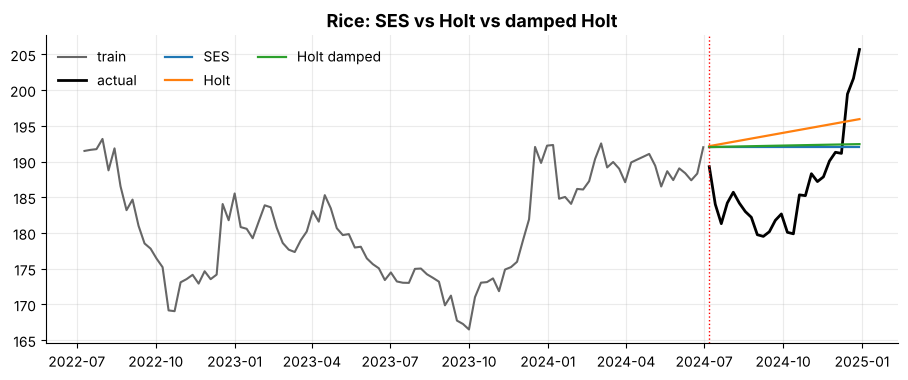

Holt alpha = 1.0  beta = 0.0


,MAE,RMSE,MAPE,sMAPE,MASE
SES,7.797,8.630,4.204,4.130,4.873
Holt damped,7.929,8.713,4.278,4.199,4.956
Holt,8.966,9.584,4.855,4.735,5.604


In [4]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
s = load_weekly('rice')['price']
train, test = s.iloc[:-26], s.iloc[-26:]
ses = SimpleExpSmoothing(train, initialization_method='estimated').fit()
holt = Holt(train, initialization_method='estimated').fit()
damp = Holt(train, damped_trend=True, initialization_method='estimated').fit()
fcs = {'SES': ses.forecast(26).values, 'Holt': holt.forecast(26).values, 'Holt damped': damp.forecast(26).values}
plot_forecasts(train, test, fcs, 'Rice: SES vs Holt vs damped Holt'); plt.show()
print('Holt alpha =', round(holt.params['smoothing_level'], 3), ' beta =', round(holt.params['smoothing_trend'], 4))
score_table(test, fcs, y_train=train)

**Why this works:** A high α (here ≈ 1) means the level reacts instantly to new data; a tiny β means the *slope* hardly ever changes. In this hold-out window rice prices have **plateaued**, so flat SES wins, while undamped Holt keeps extrapolating the earlier uptrend and overshoots: a live demonstration of why undamped trends are dangerous over long horizons. Damping is the compromise: it shrinks the extrapolated slope.

### ✅ Solution 4.4 · Additive or multiplicative? Airline passengers

**Problem recap:** Using the classic airline-passenger series (`load_airline()`), hold out the last 24 months. Fit Holt-Winters (`trend='add'`, `damped_trend=True`, `seasonal_periods=12`)
  with **additive** and with **multiplicative** seasonality. Compare RMSE with the seasonal naive baseline, plot, and explain in a comment *why* one is better.

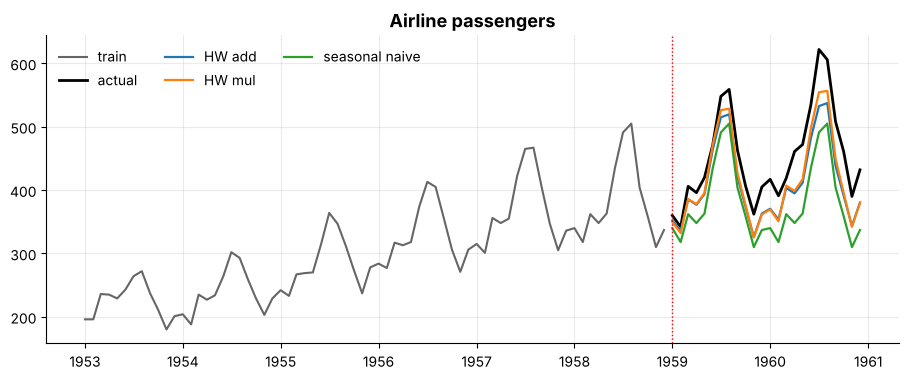

,MAE,RMSE,MAPE,sMAPE,MASE
HW mul,36.515,40.997,8.012,8.430,1.278
HW add,41.198,46.616,8.855,9.359,1.442
seasonal naive,71.250,76.995,15.523,17.013,2.494


In [5]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
air = load_airline()
train, test = air.iloc[:-24], air.iloc[-24:]
fcs = {}
for kind in ['add', 'mul']:
    fit = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal=kind, seasonal_periods=12, initialization_method='estimated').fit()
    fcs[f'HW {kind}'] = fit.forecast(24).values
fcs['seasonal naive'] = fc_snaive(train, 24, m=12)
plot_forecasts(train, test, fcs, 'Airline passengers', last_train=72); plt.show()
score_table(test, fcs, y_train=train, m=12)

**Why this works:** In the airline data the seasonal swings **grow with the level**: a percentage effect, so the multiplicative form (`level × season`) fits naturally. Additive seasonality assumes a constant-size swing, which is too big early on and too small late.

### ✅ Solution 4.5 · Holt-Winters tournament on monthly onion prices

**Problem recap:** Resample **onion** weekly prices to monthly means (`'ME'`). Hold out the last 12 months. Fit **every** reasonable Holt-Winters configuration:
  `trend ∈ {None, 'add'}`, `damped ∈ {False, True}` (only when there is a trend), `seasonal ∈ {'add', 'mul'}` (all with `seasonal_periods=12`).
  Rank them by **AICc on the training data**, then evaluate the winner and the seasonal-naive baseline on the 12 held-out months.
  Does the model chosen by AICc also win on the test set?

In [6]:
import itertools
from statsmodels.tsa.holtwinters import ExponentialSmoothing
monthly = load_weekly('onion')['price'].resample('ME').mean()
train, test = monthly.iloc[:-12], monthly.iloc[-12:]
rows = []
for trend, damped, seas in itertools.product([None, 'add'], [False, True], ['add', 'mul']):
    if trend is None and damped:
        continue
    fit = ExponentialSmoothing(train, trend=trend, damped_trend=damped, seasonal=seas, seasonal_periods=12, initialization_method='estimated').fit()
    rows.append(dict(trend=trend, damped=damped, seasonal=seas, AICc=fit.aicc, test_RMSE=rmse(test, fit.forecast(12))))
table = pd.DataFrame(rows).sort_values('AICc').reset_index(drop=True)
print(table.round(2))
print('seasonal-naive RMSE:', round(rmse(test, fc_snaive(train, 12, m=12)), 2))

  trend  damped seasonal    AICc  test_RMSE
0   NaN   False      mul  371.69       3.79
1   add   False      mul  375.85       5.58
2   add    True      mul  376.79       4.44
3   NaN   False      add  387.74       7.01
4   add   False      add  391.38       9.39
5   add    True      add  394.42       8.57
seasonal-naive RMSE: 4.54


**Why this works:** AICc rewards fit on the *training* data while penalising complexity. Here it picked a model *without* a trend but with multiplicative seasonality, and that model also won on the 12 held-out months and beat seasonal naive: a nice agreement. Notice, though, that the ranking of the *other* configurations differs between the AICc and test columns, and one 12-month test window is a small sample. AICc is a quick guide, not a guarantee; that is why we validate with walk-forward evaluation rather than trusting in-sample criteria alone.